# 05 · Using the surrogate

**Milestone 5.** The release model (notebook 04's recipe, trained by `python -m surrogate train`
and saved as one numpy-only file) is put to work: how close it is to MISS3D, whether its
uncertainty band can be trusted, which soil inputs drive the impedance, and what a Monte Carlo
study costs with it instead of with the simulator.

## In plain words

A surrogate is only useful if it is accurate, honest about its uncertainty, and fast enough to
answer questions the simulator cannot. Section 1 shows the model card. Section 2 overlays
surrogate and MISS3D for held-out soils. Section 3 checks the band: if it claims 95 %, about
95 % of the simulated values should fall inside it. Section 4 asks which strata matter, by
varying all soil inputs at once over thousands of virtual soils (Sobol indices). Section 5
propagates soil uncertainty into the impedance curves with 10,000 virtual soils. Section 6
times it all against MISS3D.

The release model `ml/models/impedance_surrogate_v1.npz` is included; `python -m surrogate train`
rebuilds it from the dataset (about 30 minutes on the GPU). Run time of this notebook: about
15 minutes.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from surrogate import style
from surrogate.analysis import monte_carlo, sobol_indices, soil_box, with_footprint
from surrogate.data import load_dataset, make_targets, targets_to_K
from surrogate.portable import DEFAULT_MODEL, INPUTS, NOMINAL, ImpedanceSurrogate

style.apply()

QUICK = False                 # True: small samples, to check that the notebook runs
MODEL = DEFAULT_MODEL         # created by: python -m surrogate train
N_SOBOL = 256 if QUICK else 2048        # Sobol base sample (a power of 2); evaluations = N x (8 + 2)
N_MC = 1000 if QUICK else 10_000         # Monte Carlo soils
N_CAL = 40 if QUICK else None            # hold-out cases for the band checks (None: all 160)

sur = ImpedanceSurrogate.load(MODEL)
ds = load_dataset()
test = ds.select(split="test")
Y_t, spec = make_targets(test.K)
K_t = targets_to_K(Y_t, spec)                       # (160, 59, 8) MISS3D
f = sur.freqs
terms = list(sur.terms)
UNITS = {"Ux": "MN/m", "Uy": "MN/m", "Uz": "MN/m", "Rx": "MN·m/rad", "Ry": "MN·m/rad", "Rz": "MN·m/rad",
         "Ux-Ry": "MN/rad", "Uy-Rx": "MN/rad"}
MESHES = style.MESH_ORDER
SOIL = INPUTS[:8]
print(f"{sur.meta['name']}: {sur.meta['n_train']} training cases, {sur.n_gp} GPs, "
      f"{f[0]:g}-{f[-1]:g} Hz ({len(f)} frequencies)")

impedance_surrogate_v1: 5120 training cases, 28 GPs, 0.45-14.95 Hz (59 frequencies)


## 1 · The model card

Stored inside the model file by `python -m surrogate train`: how it was trained, and how it did
on the 160 hold-out simulations (32 random soils per footprint, never used in training).
The error of one curve is e = 100 · max_f |K̂ − K| / max_f |K|; `err_95th` is the value that
95 % of the hold-out soils stay below.

In [2]:
m = sur.meta
print("training:", m.get("training"))
print("built:", m.get("created"), "| commit:", m.get("git_commit"), "| export check:",
      f"{m.get('export_check_max_dev_pct', float('nan')):.1g} % from the trained model")
h = m["holdout"]
print(f"hold-out: mean error {h['err_mean']:.2f} %, worst term {h['err_worst']:.2f} %, "
      f"95 % band holds {100 * h['band95_coverage']:.1f} % of the values, {h['predict_ms_per_case']:.2f} ms per case")
pd.DataFrame({"err_95th [%]": h["err_95th"]}).T.round(2)

training: {'n_soils_per_footprint': 512, 'rotated_twins': True, 'n_cases': 5120, 'engine': 'GPyTorch batch GPs, Adam 1000 steps', 'device': 'cuda: NVIDIA GeForce RTX 5070 Ti', 'fit_s': 1632.1, 'gpu_fit': {'precision': 'float32', 'noise_floor': 0.001024, 'jitter_events': 0, 'max_jitter': 0.0, 'refit_in_float64': 0, 'predict_in_float64': 0}}
built: 2026-10-06 | commit: 7fc6ca1+dirty | export check: 0.1 % from the trained model
hold-out: mean error 2.91 %, worst term 8.61 %, 95 % band holds 97.9 % of the values, 3.58 ms per case


,Ux,Uy,Uz,Rx,Ry,Rz,Ux-Ry,Uy-Rx
err_95th [%],6.33,7.04,3.44,3.16,3.36,4.42,8.61,7.04


In [3]:
pd.DataFrame({"mean error [%]": h["err_mean_per_footprint"]}).T.round(2)

,m30x15,m45x15,m60x15,m80x20,ref33x31
mean error [%],2.43,2.54,2.82,4.01,2.75


## 2 · Surrogate against MISS3D

The hold-out case with the median error and the one with the largest error, for three terms
(horizontal, vertical, rocking). Line: surrogate; shaded: its 95 % band; circles: MISS3D.

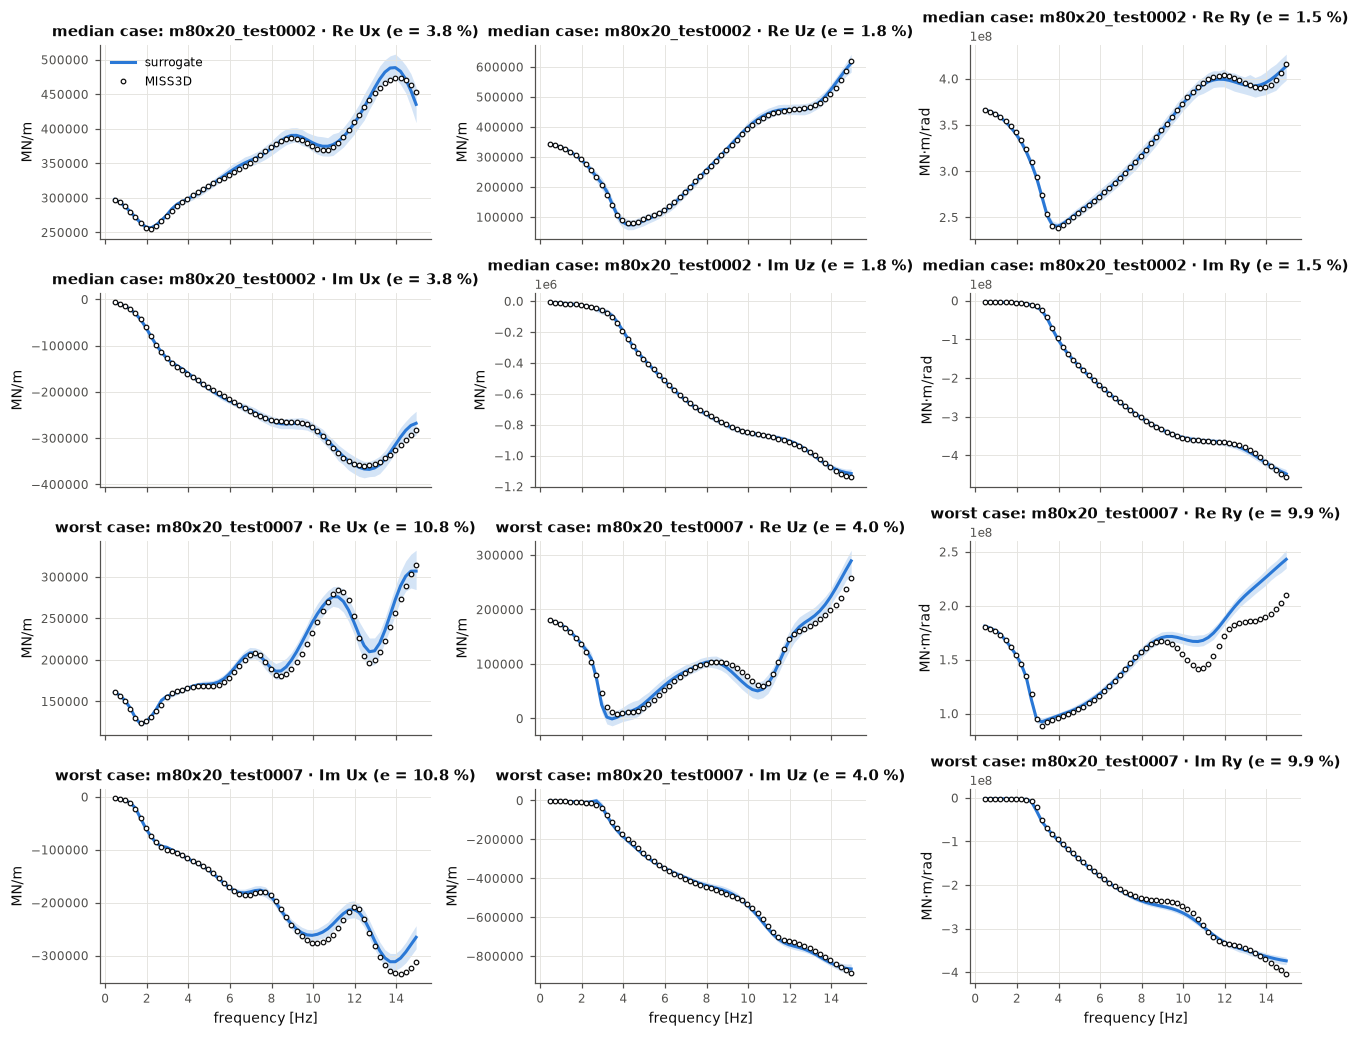

In [4]:
pred = sur.predict(test.X, band=True)
err = 100 * np.abs(pred.K - K_t).max(axis=1) / np.abs(K_t).max(axis=1)      # (160, 8)
order = np.argsort(err.mean(axis=1))
picks = {"median case": order[len(order) // 2], "worst case": order[-1]}
SHOW = ["Ux", "Uz", "Ry"]

fig, axes = plt.subplots(len(picks) * 2, len(SHOW), figsize=(12, 9.5), sharex=True)
for r, (label, i) in enumerate(picks.items()):
    for c, t in enumerate(SHOW):
        k = terms.index(t)
        for p, part in enumerate([np.real, np.imag]):
            ax = axes[2 * r + p, c]
            ax.fill_between(f, part(pred.lo[i, :, k]), part(pred.hi[i, :, k]), color=style.SERIES[0], alpha=0.2, lw=0)
            ax.plot(f, part(pred.K[i, :, k]), color=style.SERIES[0], label="surrogate")
            ax.plot(f, part(K_t[i, :, k]), "o", ms=3, mfc="white", mec=style.INK, mew=0.8, label="MISS3D")
            ax.set_title(f"{label}: {test.case[i]} · {'Re' if p == 0 else 'Im'} {t} (e = {err[i, k]:.1f} %)")
            ax.set_ylabel(UNITS[t])
for ax in axes[-1]:
    ax.set_xlabel("frequency [Hz]")
axes[0, 0].legend()
fig.tight_layout()

### 2b · Where the error comes from

Rebuild every hold-out curve from its own exact 28 numbers (true static values and true PCA
weights of its shape): what is left is the error of the 20-component compression alone, the
floor that perfect GPs would reach. The difference to the model's error is what the GPs add.

In [5]:
from surrogate.data import terms_to_targets
s_true = K_t[:, 0, :].real
shape_true = terms_to_targets(K_t / s_true[:, None, :])
A_true = (shape_true - sur.a["pca_mean"]) @ sur.a["pca_components"].T
K_floor = targets_to_K(sur.a["pca_mean"] + A_true @ sur.a["pca_components"], spec) * s_true[:, None, :]
e_floor = 100 * np.abs(K_floor - K_t).max(axis=1) / np.abs(K_t).max(axis=1)
budget = pd.DataFrame({"model": err.mean(axis=0), "PCA floor (perfect GPs)": e_floor.mean(axis=0)},
                      index=terms)
budget.loc["all terms"] = [err.mean(), e_floor.mean()]
budget["share of the error from the PCA [%]"] = 100 * budget["PCA floor (perfect GPs)"] / budget["model"]
budget.round(2)

,model,PCA floor (perfect GPs),share of the error from the PCA [%]
Ux,3.50,2.54,72.62
Uy,3.58,2.62,73.26
Uz,1.93,1.65,85.62
Rx,1.77,1.77,100.14
Ry,1.80,1.72,95.55
Rz,2.23,2.03,90.63
Ux-Ry,4.57,3.85,84.11
Uy-Rx,3.88,3.31,85.39
all terms,2.91,2.44,83.78


## 3 · Is the band honest?

**Calibration.** For bands at several levels, the share of the simulated values (every term,
frequency, Re and Im, all hold-out cases) that fall inside. A well-calibrated model sits on the
diagonal; above it the band is cautious (too wide), below it over-confident.

**What the band contains.** Two sources of uncertainty, combined by sampling:
1. the GPs' uncertainty about the 28 numbers. The exact GP variance needs each GP's full n × n
   Cholesky factor, too large to ship, so the model computes it from the 128 training cases
   nearest to the new input, which can only overstate it;
2. what the 20 PCA components leave out of the shape (the truncation error), measured on the
   training curves. Section 2b shows that it is most of the remaining error.

The table measures, for several neighbour counts, how much wider than exact the GP part is, how
the band then covers the simulations, and what each costs.

,50 %,68 %,80 %,90 %,95 %,99 %
inside [%],73.1,86.6,92.8,96.5,97.9,99.1


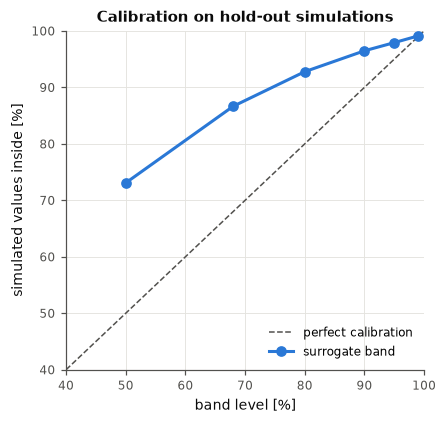

In [6]:
cal = np.arange(len(test)) if N_CAL is None else order[np.linspace(0, len(order) - 1, N_CAL).astype(int)]
Xc, Kc = test.X[cal], K_t[cal]

def inside(p, K):
    ok_re = (K.real >= p.lo.real) & (K.real <= p.hi.real)
    ok_im = (K.imag >= p.lo.imag) & (K.imag <= p.hi.imag)
    return 0.5 * (ok_re.mean() + ok_im.mean())

levels = [50, 68, 80, 90, 95, 99]
coverage = {L: inside(sur.predict(Xc, band=True, level=L), Kc) for L in levels}
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([40, 100], [40, 100], color=style.INK2, lw=1, ls="--", label="perfect calibration")
ax.plot(levels, [100 * coverage[L] for L in levels], "o-", color=style.SERIES[0], label="surrogate band")
ax.set(xlim=(40, 100), ylim=(40, 100), xlabel="band level [%]", ylabel="simulated values inside [%]",
       title="Calibration on hold-out simulations")
ax.legend(loc="lower right")
pd.Series({f"{L} %": round(100 * coverage[L], 1) for L in levels}, name="inside [%]").to_frame().T

In [7]:
G, S_exact = sur.gp_outputs(Xc, return_std=True, n_neighbours=10**9)     # exact variance (slow: n x n per GP)
rows = {}
for nn in [32, 64, 128, 256, 512]:
    t0 = time.perf_counter()
    _, S = sur.gp_outputs(Xc, return_std=True, n_neighbours=nn)
    ms = 1000 * (time.perf_counter() - t0) / len(Xc)
    ratio = S / S_exact
    rows[nn] = {"std / exact, median": np.median(ratio), "std / exact, 90th pct": np.percentile(ratio, 90),
                "95 % band holds [%]": 100 * inside(sur.predict(Xc, band=True, n_neighbours=nn), Kc),
                "ms per case (variance)": ms}

class Band:                                          # band edges from given GP standard deviations
    def __init__(self, S, truncation=True):
        self.lo, self.hi = sur.band_from_gp(G, S, truncation=truncation)
rows["exact"] = {"std / exact, median": 1.0, "std / exact, 90th pct": 1.0,
                 "95 % band holds [%]": 100 * inside(Band(S_exact), Kc), "ms per case (variance)": np.nan}
_, S128 = sur.gp_outputs(Xc, return_std=True)
rows["128, GP part only"] = {"std / exact, median": np.median(S128 / S_exact), "std / exact, 90th pct": np.nan,
                             "95 % band holds [%]": 100 * inside(Band(S128, truncation=False), Kc),
                             "ms per case (variance)": np.nan}
pd.DataFrame(rows).T.round(2)

,"std / exact, median","std / exact, 90th pct",95 % band holds [%],ms per case (variance)
32,1.95,2.58,98.93,5.12
64,1.61,1.99,98.46,8.11
128,1.35,1.59,97.92,111.75
256,1.19,1.32,97.51,281.71
512,1.09,1.17,97.23,778.71
exact,1.00,1.00,96.88,NaN
"128, GP part only",1.35,NaN,90.11,NaN


## 4 · Which soil inputs matter?

Sobol indices for the 45 × 15 m raft: all eight soil inputs vary together, uniformly over their
training ranges (g log-uniformly, as in the dataset design), and the variance of an output is
split into the shares each input explains. **ST** (total index) counts an input's effect alone
and through interactions; ST ≈ 0 means the input could be fixed without changing the answer.
This uses N × (8 + 2) predictions. Because g scales the shear modulus of every stratum, it is
expected to dominate the static stiffness; the second map repeats the question with g known.

First the static stiffness of each term, then the frequency dependence: the indices of the
*shape* |K(f)| / |K_static|, which shows which strata create the ripples at each frequency.

20480 predictions in 93.2 s


Ux     Uy     Uz     Rx     Ry     Rz  Ux-Ry  Uy-Rx
all vary t_L1      0.001  0.001  0.002  0.009  0.001  0.003  0.019  0.018
         t_L2      0.002  0.002  0.007  0.001  0.006  0.000  0.000  0.002
         t_L3      0.003  0.003  0.018  0.001  0.011  0.000  0.009  0.012
         t_L4      0.000  0.000  0.002  0.000  0.001  0.000  0.001  0.001
         t_L5      0.001  0.001  0.009  0.000  0.000  0.000  0.003  0.000
         t_L6      0.000  0.001  0.004  0.000  0.000  0.000  0.001  0.000
         t_L7      0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
         g_factor  0.992  0.992  0.958  0.989  0.981  0.996  0.967  0.966
g = 1    t_L1      0.186  0.119  0.050  0.819  0.053  0.798  0.569  0.531
         t_L2      0.288  0.271  0.169  0.104  0.332  0.121  0.011  0.069
         t_L3      0.337  0.388  0.429  0.081  0.571  0.081  0.266  0.356
         t_L4      0.032  0.037  0.044  0.009  0.063  0.008  0.033  0.042
         t_L5      0.109  0.125  0.211  0.001  0.013  0.001  0.095  0.007
         t_L6      0.057  0.065  0.097  0.000  0.006  0.000  0.039  0.002
         t_L7      0.008  0.009  0.010  0.000  0.000  0.000  0.001  0.000

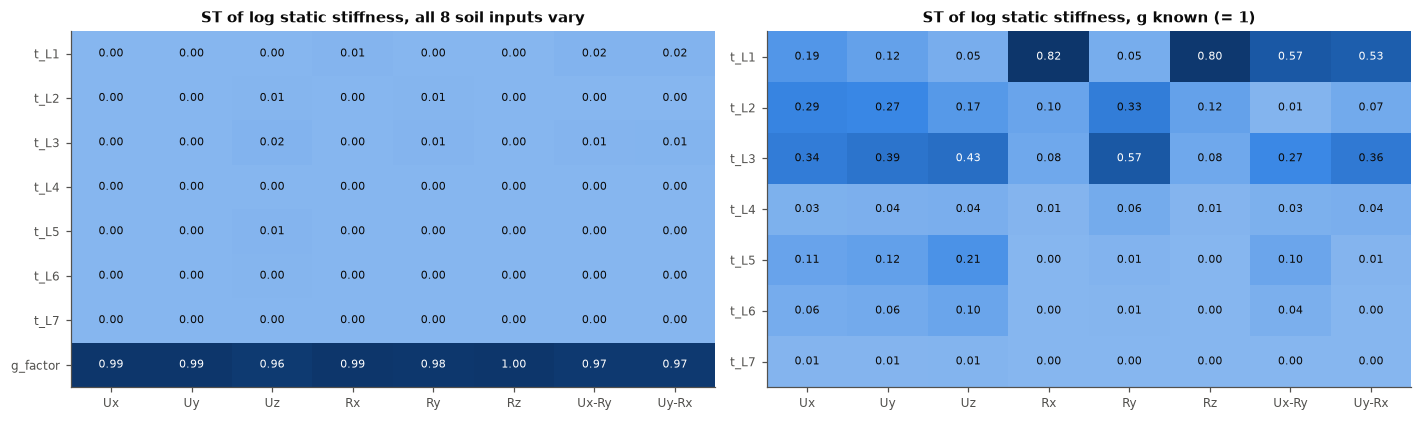

In [8]:
lo, hi = soil_box(sur)
LX, LY = 45.0, 15.0
log_static = lambda S: sur.gp_outputs(with_footprint(S, LX, LY))[:, :len(terms)]
t0 = time.perf_counter()
sob = sobol_indices(log_static, lo, hi, n=N_SOBOL, log_cols=[7])
print(f"{sob['n_eval']} predictions in {time.perf_counter() - t0:.1f} s")
# the same question when the stiffness is known (g = 1): which thicknesses matter?
with_g1 = lambda T: np.column_stack([T, np.ones(len(T))])
sob_g1 = sobol_indices(lambda T: log_static(with_g1(T)), lo[:7], hi[:7], n=N_SOBOL)

def heat(ax, M, rows, title):
    ax.imshow(M, cmap=style.SEQ, vmin=0, vmax=max(M.max(), 1e-9), aspect="auto")
    ax.set_xticks(range(len(terms)), terms)
    ax.set_yticks(range(len(rows)), rows)
    ax.grid(False)
    for (r, c), v in np.ndenumerate(M):
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if v > 0.5 * M.max() else style.INK)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
heat(axes[0], sob["ST"], SOIL, "ST of log static stiffness, all 8 soil inputs vary")
heat(axes[1], sob_g1["ST"], SOIL[:7], "ST of log static stiffness, g known (= 1)")
fig.tight_layout()
pd.concat({"all vary": pd.DataFrame(sob["ST"], index=SOIL, columns=terms),
           "g = 1": pd.DataFrame(sob_g1["ST"], index=SOIL[:7], columns=terms)}).round(3)

10240 predictions in 47.2 s


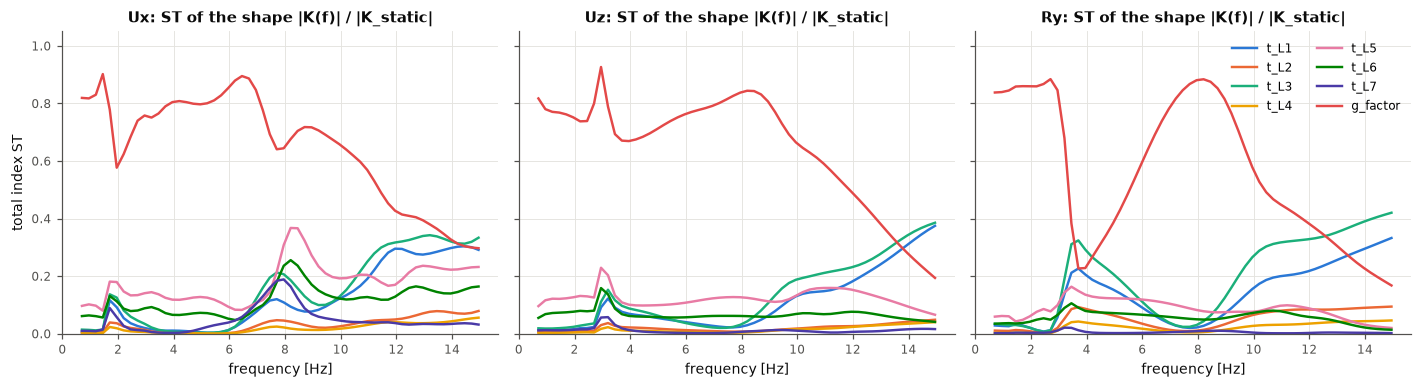

In [9]:
SHAPE_TERMS = ["Ux", "Uz", "Ry"]
ks = [terms.index(t) for t in SHAPE_TERMS]
def shape_abs(S):
    p = sur.predict(with_footprint(S, LX, LY))
    return (np.abs(p.K[:, :, ks]) / np.abs(p.static[:, None, ks])).reshape(len(S), -1)   # (m, 59 x 3)
t0 = time.perf_counter()
sob_f = sobol_indices(shape_abs, lo, hi, n=N_SOBOL // 2, log_cols=[7], n_boot=50)
print(f"{sob_f['n_eval']} predictions in {time.perf_counter() - t0:.1f} s")
STf = sob_f["ST"].reshape(len(SOIL), len(f), len(ks))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for a, (ax, t) in enumerate(zip(axes, SHAPE_TERMS)):
    for i, name in enumerate(SOIL):
        ax.plot(f[1:], STf[i, 1:, a], color=style.SERIES[i], lw=1.6, label=name)
    ax.set(title=f"{t}: ST of the shape |K(f)| / |K_static|", xlabel="frequency [Hz]", ylim=(0, 1.05))
axes[0].set_ylabel("total index ST")
axes[-1].legend(ncol=2, loc="upper right")
fig.tight_layout()

## 5 · Soil uncertainty in, impedance uncertainty out

A design case: the mid-range soil (every thickness at the middle of its range, g = 1) under the 45 × 15 m
raft, with illustrative uncertainty: each thickness normal with a coefficient of variation of
10 %, and g log-normal with a factor 1.25 at two standard deviations. N_MC random soils go
through the surrogate. The bands show the 16–84 % and 2.5–97.5 % ranges of K(f) caused by the
soil; the dashed lines show the surrogate's own 95 % band at the nominal soil, i.e. how much of
the spread could be model error.

10000 soils in 46.0 s with the surrogate; with MISS3D: 183 core-hours (7.6 days on one core)


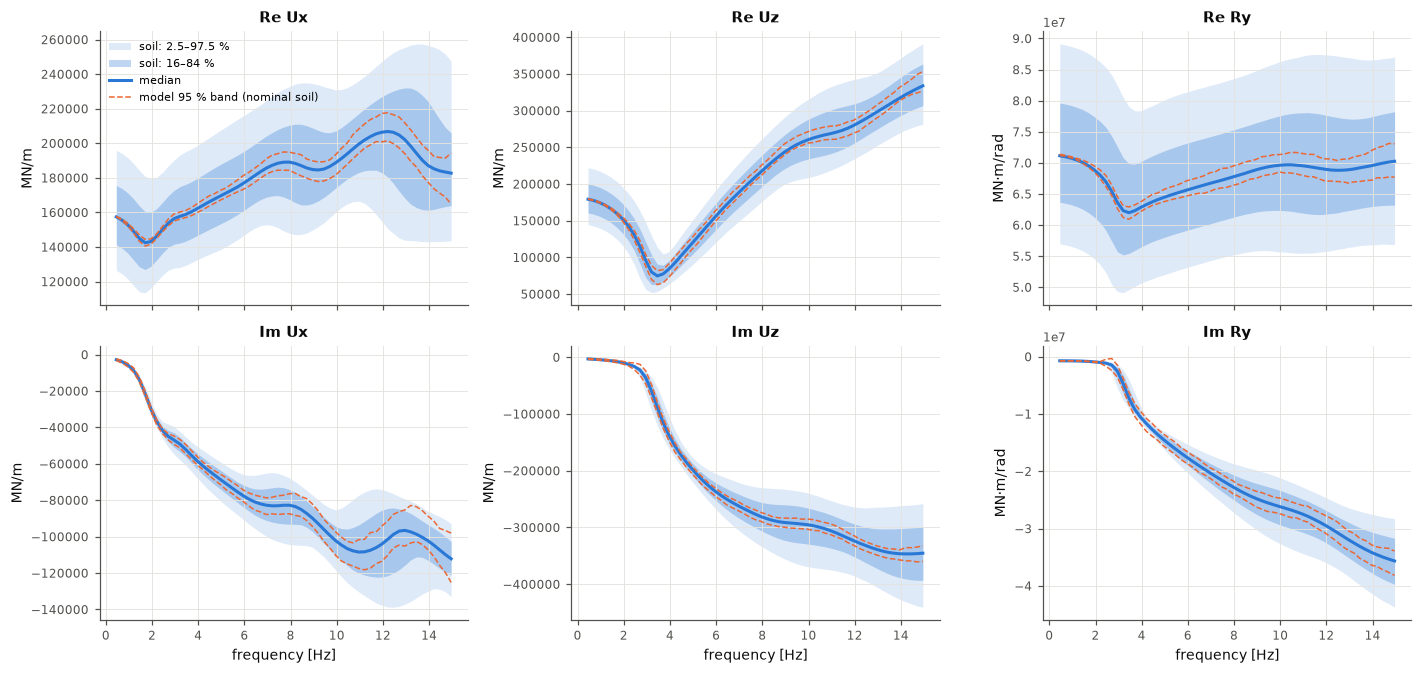

In [10]:
base = dict(NOMINAL, L_x=LX, L_y=LY)
mc = monte_carlo(sur, base, n=N_MC, cov_thickness=0.10, g_factor_spread=1.25)
nom = sur.predict(base, band=True)
miss3d_s = 66.0                      # one MISS3D run of the 45 x 15 m raft, single job (timing test, 2 October)
print(f"{mc['n']} soils in {mc['seconds']:.1f} s with the surrogate; "
      f"with MISS3D: {mc['n'] * miss3d_s / 3600:.0f} core-hours ({mc['n'] * miss3d_s / 86400:.1f} days on one core)")

fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), sharex=True)
for c, t in enumerate(SHAPE_TERMS):
    k = terms.index(t)
    for r, (key, part) in enumerate([("re", np.real), ("im", np.imag)]):
        ax = axes[r, c]
        q = mc[key][:, :, k]
        ax.fill_between(f, q[0], q[4], color=style.SERIES[0], alpha=0.15, lw=0, label="soil: 2.5–97.5 %")
        ax.fill_between(f, q[1], q[3], color=style.SERIES[0], alpha=0.3, lw=0, label="soil: 16–84 %")
        ax.plot(f, q[2], color=style.SERIES[0], label="median")
        ax.plot(f, part(nom.lo[0, :, k]), "--", color=style.SERIES[1], lw=1, label="model 95 % band (nominal soil)")
        ax.plot(f, part(nom.hi[0, :, k]), "--", color=style.SERIES[1], lw=1)
        ax.set_title(f"{'Re' if r == 0 else 'Im'} {t}")
        ax.set_ylabel(UNITS[t])
for ax in axes[-1]:
    ax.set_xlabel("frequency [Hz]")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()

In [11]:
spread = pd.DataFrame({
    "static, median": mc["static"][2],
    "static 16-84 % [± %]": 50 * (mc["static"][3] - mc["static"][1]) / np.abs(mc["static"][2]),
    "model 95 % band at nominal [± %]": 50 * np.abs(nom.hi[0, 0].real - nom.lo[0, 0].real) / np.abs(nom.static[0]),
}, index=terms)
spread.round(3)

,"static, median",static 16-84 % [± %],model 95 % band at nominal [± %]
Ux,1.574045e+05,10.919,0.076
Uy,1.697594e+05,10.930,0.081
Uz,1.792094e+05,10.993,0.115
Rx,1.525120e+07,11.030,0.102
Ry,7.113962e+07,11.209,0.114
Rz,6.365558e+07,11.031,0.241
Ux-Ry,-3.233678e+05,11.211,0.139
Uy-Rx,1.674977e+05,11.111,0.128


## 6 · Speed

Prediction times on this machine, against one MISS3D run per footprint (single job, timing
test of 2 October; under 8 parallel jobs the runs took about 20 % longer).

In [12]:
def per_case(fn, X, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); fn(X); best = min(best, time.perf_counter() - t0)
    return 1000 * best / len(X)

X1 = test.X[:1]
X1000 = np.repeat(test.X, 7, axis=0)[:1000]
speed = pd.Series({
    "one case, curves only [ms]": per_case(lambda X: sur.predict(X), X1),
    "one case, with 95 % band [ms]": per_case(lambda X: sur.predict(X, band=True), X1),
    "batch of 1,000, per case [ms]": per_case(lambda X: sur.predict(X), X1000, repeat=1),
}).round(3)
miss3d = pd.Series({"m30x15": 20, "m45x15": 66, "m60x15": 66, "m80x20": 433, "ref33x31": 102}, name="MISS3D [s per run]")
display(speed.to_frame("surrogate"))
miss3d.to_frame().T

,surrogate
"one case, curves only [ms]",3.643
"one case, with 95 % band [ms]",132.042
"batch of 1,000, per case [ms]",5.169


,m30x15,m45x15,m60x15,m80x20,ref33x31
MISS3D [s per run],20,66,66,433,102


## 7 · Using the model outside this notebook

    python -m surrogate predict ml/examples/nominal_45x15.json --band --csv curves.csv
    python -m surrogate serve                 # API on http://127.0.0.1:8000/docs (POST /predict)
    python -m surrogate viewer                # ml/viewer/index.html: the interactive page, works offline

The API and the viewer use the same file and the same arithmetic as this notebook
(`surrogate/portable.py`); the API needs only numpy, FastAPI and uvicorn (`ml/Dockerfile`).

## 8 · Findings (release model of 6 October 2026, notebook run of 18 October 2026)

- **Accuracy (sections 1–2).** A 2.9 % mean error on the 160 hold-out simulations; for 95 % of
  soils every term is within 8.6 % (the Ux–Ry coupling is the hardest, rocking within 3.4 %).
- **Where the error is (2b).** Rebuilding each curve from its own exact 28 numbers leaves 2.4 %:
  84 % of the error is the 20-component PCA, not the GPs (100 % for Rx, 73 % for Ux). The next
  lever is more components: on the hold-out shapes the floor is 1.2 % at 40 components and
  0.6 % at 60, to be chosen on a validation set (`python -m surrogate train --validate`).
- **The band (3).** The 95 % band holds 97.9 % of the simulated values and is cautious at every
  level (the 50 % band holds 73 %, the 90 % band 96.5 %). Without the PCA term it held 90.1 %:
  the GPs were honest about their own numbers, but the band missed the compression error. With
  the exact GP variance it would hold 96.9 %, so the 128-neighbour shortcut adds about one point
  of caution, at about 0.1 s per case.
- **What drives the static stiffness (4).** Within the training ranges, g explains 96–100 % of
  the variance of every static term: it scales the modulus of all seven strata. With g known,
  the top stratum L1 governs rocking about x and torsion (ST 0.80–0.82) and the couplings
  (0.53–0.57); L3 governs the vertical term (0.43) and rocking about y (0.57), with L2 second;
  the soft L5 adds to the vertical term (0.21); the deepest stratum L7 hardly matters (≤ 0.01).
  Rocking about the long axis and torsion of the 15 m-wide raft depend on shallow soil, rocking
  along its 45 m length on deeper soil: consistent with a depth of influence that grows with the
  loaded dimension.
- **What drives the curve shape (4).** g leads up to about 11 Hz, with the soft strata L5 and
  L6 second: their contrast creates the ripples. Near 14 Hz the shallow strata L3 and L1 take
  over, as the wavelengths shorten.
- **Soil uncertainty against model uncertainty (5).** A thickness CoV of 10 % and g within
  ×/÷ 1.25 (2σ) give ±11 % on every static term (16–84 %), set almost entirely by g. The model's
  own 95 % band at the nominal soil is ±0.08–0.24 %. Along frequency the soil spread stays 4–14
  times the model's standard deviation up to 10 Hz and 3–6 times at 15 Hz: accurate enough for
  this kind of study, with the margin narrowing at the top of the band.
- **Speed (6).** 3.6 ms for one case, 3.6–5.2 ms per case in batches (timings vary from run to
  run), 0.13 s with the band, against 20 s to 7 min per MISS3D run: 5,000 to 100,000 times
  faster. A 10,000-soil Monte Carlo takes under a minute (46 s here) instead of about 180
  core-hours.